In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.distributions import Categorical

import os

In [2]:
# virtual patient model parameters
PATIENT = {
    "rS": 0.027,   # sensitive proliferation rate  [1/day]
    "rR": 0.027,   # resistant proliferation rate  [1/day]
    "dS": 0.0,     # sensitive natural death rate
    "dR": 0.0,     # resistant natural death rate
    "dD": 1.5,     # drug-induced death factor on sensitive cells
    "K":  1.0,     # carrying capacity (tumour size normalised to K)
    "S0": 0.74,    # initial sensitive population
    "R0": 0.01,    # initial resistant population
    "DMax": 1.0,   # drug concentration when treating
}

# weekly monitoring / decision interval
DT_DAYS = 7          

# Reward / episode parameters (Gallagher et al. 2024, Table 1 & parameters.md)
REWARD = {
    "base":   0.1,        # reward per monitoring step survived
    "hol":    0.05,       # bonus for taking a treatment holiday
    "punish": -0.1,       # penalty at progression / for risky holidays
    "survival_bonus": 5.0,  # reward for reaching the survival horizon
    "progression_factor": 1.2,   # progression when tumour > 1.2 * n0
    "horizon_days": 20 * 365,    # 20-year survival cap
}

# Action encoding
HOLIDAY = 0
TREAT = 1
# 2 actions in total
N_ACTIONS = 2

In [3]:
# simulator

class CancerTreatmentEnv:
    """Lotka-Volterra virtual patient as an RL environment.
    dt : float
        Days between monitoring/decision points (default 7 = weekly,
        matching the clinical AT protocols the paper compares against).
    patient : dict, optional
        Overrides for the Lotka-Volterra parameters in ``DEFAULT_PATIENT``.
        Pass a per-patient dict to model a heterogeneous cohort.
    reward : dict, optional
        Overrides for the reward parameters in ``DEFAULT_REWARD``.
    """
    def __init__(self, patient, reward, dt=DT_DAYS):
        self.p = {**patient}
        self.r = {**reward}
        self.dt = float(dt)

        self.n0 = self.p["S0"] + self.p["R0"]          # initial tumour burden
        self.progression = self.r["progression_factor"] * self.n0
        self.progression_factor = self.r["progression_factor"]

        self.S = self.R = self.t = self.D = None
        self.reset()
        self.n_observations = 2
        self.n_actions = N_ACTIONS

    # Core dynamics
    def _rhs(self, _t, y, D):
        """Right-hand side of the Lotka-Volterra ODEs for a fixed dose D."""
        S, R = y
        comp = 1.0 - (S + R) / self.p["K"]
        dS = self.p["rS"] * comp * (1.0 - self.p["dD"] * D) * S - self.p["dS"] * S
        dR = self.p["rR"] * comp * R - self.p["dR"] * R
        return [dS, dR]

    def _observe(self):
        """Observable state: normalised tumour burden and current treatment status."""
        return np.array([(self.S + self.R) / self.n0,
                         self.D / self.p["DMax"]], dtype=np.float32)

    def reset(self):
        """Reset to the initial tumour composition and return the observation."""
        self.S = self.p["S0"]
        self.R = self.p["R0"]
        self.t = 0.0
        self.D = 0.0          # start off-treatment
        return self._observe()

    def step(self, action):
        self.D = self.p["DMax"] if action == TREAT else 0.0
        sol = solve_ivp(self._rhs, [0.0, self.dt], [self.S, self.R],
                        args=(self.D,), rtol=1e-6, atol=1e-9, dense_output=False)
        self.S, self.R = sol.y[0, -1], sol.y[1, -1]
        self.t += self.dt

        tumour = self.S + self.R
        reward, done = self._reward(tumour, action)

        info = {"S": self.S, "R": self.R, "tumour": tumour,
                "dose": self.D, "time": self.t}
        return self._observe(), reward, done, info

    def _reward(self, tumour, action):
        done = False
        reward = self.r["base"]                     # survived another step

        if tumour > self.progression:               # disease progression
            return self.r["punish"], True
        if self.t >= self.r["horizon_days"]:         # reached survival cap
            return reward + self.r["survival_bonus"], True

        if action == HOLIDAY:
            if tumour > self.n0:                     # risky holiday near baseline
                reward += self.r["punish"]
            reward += self.r["hol"]                  # reward for sparing the drug
        return reward, done

In [4]:
# rollout function to evaluate policies
def rollout(env, policy):
    """Run one episode with the given policy(obs)->action, recording the trace."""
    obs = env.reset()
    trace = {"t": [0.0], "S": [env.S], "R": [env.R],
             "tumour": [env.S + env.R], "dose": [], "reward": 0.0}
    done = False
    while not done:
        action = policy(env, obs)
        obs, reward, done, info = env.step(action)
        trace["t"].append(info["time"])
        trace["S"].append(info["S"])
        trace["R"].append(info["R"])
        trace["tumour"].append(info["tumour"])
        trace["dose"].append(info["dose"])
        trace["reward"] += reward
    return trace

# plotting function to visualize policies
def plot_results(ax1, ax2, trace, env):
    """Plot the tumour dynamics and treatment schedule from a rollout trace."""
    t = np.array(trace["t"]) / 30.4  # months
    initial_S = trace["S"][0]
    initial_R = trace["R"][0]
    initial_N = initial_S + initial_R
    ax1.plot(t[:-1], np.array(trace["S"])[:-1]/initial_N, label="sensitive S", color="C0")
    ax1.plot(t[:-1], np.array(trace["R"])[:-1]/initial_N, label="resistant R", color="C3")
    ax1.plot(t[:-1], (np.array(trace["S"]) + np.array(trace["R"]))[:-1]/initial_N, label="total burden", color="k", lw=2)
    ax1.axhline(env.progression_factor, color="0.5", ls="--", lw=1,
                label="progression threshold")
    ax1.set_ylabel("population (fraction of N0)")
    ax1.legend()

    dose = np.array(trace["dose"])
    ax2.step(t[:-1], dose, where="pre", color="C2")
    ax2.fill_between(t[:-1], 0, dose, step="pre", alpha=0.3, color="C2")
    ax2.set_yticks([HOLIDAY, TREAT])
    ax2.set_yticklabels(["holiday", "treat"])
    ax2.set_xlabel("time (months)")
    ax2.set_ylabel("decision")

    ax1.axvline(t[-2], color="C1", ls="--", lw=1)
    ax2.axvline(t[-2], color="C1", ls="--", lw=1)

In [5]:
env = CancerTreatmentEnv(patient=PATIENT, reward=REWARD, dt=DT_DAYS)

In [6]:
# define 2 baseline policiies: continuous therapy and AT50 (treat down to 50% of initial size, hold up to initial size)

def ct_policy(env, obs):
    """Continuous therapy: always treat."""
    return TREAT

def at50_policy(env, obs):
    """Adaptive-therapy rule: OFF at 50% of initial size, ON at initial size."""
    tumour = env.S + env.R
    if env.D > 0:                       # currently treating
        return HOLIDAY if tumour <= 0.5 * env.n0 else TREAT
    else:                               # currently on holiday
        return TREAT if tumour >= env.n0 else HOLIDAY

In [7]:
# simulate and visualise CT and AT50 policies
strategies = [("Continuous treatment", ct_policy), ("AT50 adaptive therapy", at50_policy)]
traces = [(name, rollout(env, pol)) for name, pol in strategies]
print(f"{'strategy':<24}{'TTP (days)':>12}{'TTP (months)':>14}{'reward':>9}")
for name, tr in traces:
    ttp = tr["t"][-1]
    print(f"{name:<24}{ttp:>12.0f}{ttp / 30.4:>14.1f}{tr['reward']:>9.2f}")


strategy                  TTP (days)  TTP (months)   reward
Continuous treatment             364          12.0     5.00
AT50 adaptive therapy            462          15.2     6.75


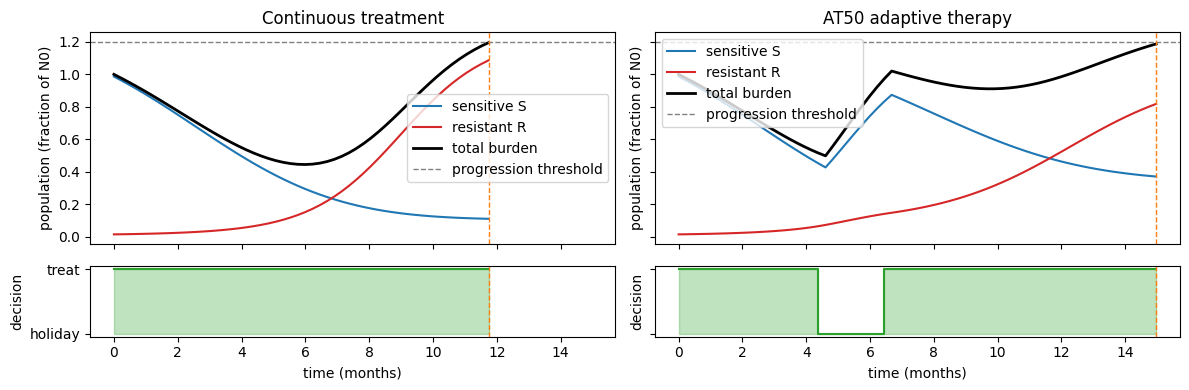

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 4), sharex=True, gridspec_kw={"height_ratios": [3, 1]}, sharey = 'row')
for i in range(2):
    axes[0, i].set_title(strategies[i][0])
    plot_results(axes[0, i], axes[1, i], traces[i][1], env)
plt.tight_layout()

In [9]:
# define reinforcement learning agent
AGENT_KWARGS = dict(
    hidden=(128, 128, 64),   # the "deep MLP"
    lr=1e-3,
    gamma=0.99,
    value_coef=0.5,
    entropy_coef=0.01,       # exploration pressure; keeps holidays on the menu
)
N_EPISODES = 4000
SEED = 0

class ActorCritic(nn.Module):
    """Deep MLP with a shared trunk and separate policy / value heads."""
    def __init__(self, n_in, n_out, hidden):
        super().__init__()
        sizes = [n_in, *hidden]
        self.trunk = nn.ModuleList(nn.Linear(a, b) for a, b in zip(sizes[:-1], sizes[1:]))
        self.policy_head = nn.Linear(sizes[-1], n_out)   # action logits
        self.value_head = nn.Linear(sizes[-1], 1)        # state-value baseline

    def forward(self, x):
        for layer in self.trunk:
            x = F.relu(layer(x))
        return self.policy_head(x), self.value_head(x)

class PGAgent:
    """Advantage actor-critic agent.

    Parameters
    ----------
    n_obs, n_actions : int
        Observation and action dimensions of the environment.
    hidden : tuple of int
        Hidden-layer widths of the MLP.
    lr : float
        Adam learning rate.
    gamma : float
        Discount factor.  Close to 1 because the payoff (long-horizon survival)
        accrues over many steps.
    value_coef : float
        Weight of the value (critic) loss in the combined objective.
    entropy_coef : float
        Weight of the entropy bonus; keeps the policy stochastic so it keeps
        sampling -- and learning from -- holiday-rich schedules.
    seed : int
        Seed for torch/numpy RNGs.
    """

    def __init__(self, n_obs, n_actions, hidden=(128, 128, 64), lr=1e-3,
                 gamma=0.99, value_coef=0.5, entropy_coef=0.01, seed=0):
        torch.manual_seed(seed)
        self.n_actions = n_actions
        self.gamma = gamma
        self.value_coef = value_coef
        self.entropy_coef = entropy_coef

        self.net = ActorCritic(n_obs, n_actions, hidden)
        self.optimizer = torch.optim.Adam(self.net.parameters(), lr=lr)

    # ------------------------------------------------------------------ #
    def choose_action(self, obs, greedy=False):
        """Sample an action from the policy; ``greedy=True`` takes the argmax."""
        with torch.no_grad():
            logits, _ = self.net(torch.as_tensor(obs, dtype=torch.float32))
            if greedy:
                return int(torch.argmax(logits).item())
            return int(Categorical(logits=logits).sample().item())

    # ------------------------------------------------------------------ #
    def _returns(self, rewards):
        """Discounted return-to-go G_t for each step of an episode."""
        g, out = 0.0, np.empty(len(rewards), dtype=np.float32)
        for i in reversed(range(len(rewards))):
            g = rewards[i] + self.gamma * g
            out[i] = g
        return out

    def update(self, states, actions, rewards):
        """One actor-critic gradient step from a single episode.

        Parameters
        ----------
        states : list of np.ndarray
        actions : list of int
        rewards : list of float

        Returns
        -------
        float : the combined loss value (for logging).
        """
        states = torch.as_tensor(np.array(states), dtype=torch.float32)
        actions = torch.as_tensor(actions, dtype=torch.int64)
        returns = torch.as_tensor(self._returns(rewards))

        logits, values = self.net(states)
        values = values.squeeze(1)
        dist = Categorical(logits=logits)

        # Advantage = (Monte-Carlo return) - (critic baseline). Detached so the
        # baseline only trains the critic, not the policy.
        advantage = returns - values.detach()

        policy_loss = -(dist.log_prob(actions) * advantage).mean()
        value_loss = F.mse_loss(values, returns)
        entropy = dist.entropy().mean()

        loss = (policy_loss
                + self.value_coef * value_loss
                - self.entropy_coef * entropy)

        self.optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(self.net.parameters(), 1.0)
        self.optimizer.step()
        return float(loss.item())

    # ------------------------------------------------------------------ #
    def save(self, path):
        torch.save(self.net.state_dict(), path)

    def load(self, path):
        self.net.load_state_dict(torch.load(path, map_location="cpu"))

# helper function to run one episode and collect the trajectory
def run_episode(env, agent, greedy=False):
    """Run one episode; collect the trajectory and return it with the totals."""
    obs = env.reset()
    states, actions, rewards = [], [], []
    done = False
    while not done:
        action = agent.choose_action(obs, greedy=greedy)
        next_obs, reward, done, info = env.step(action)
        states.append(obs)
        actions.append(action)
        rewards.append(reward)
        obs = next_obs
    return states, actions, rewards, info["time"]

In [10]:
# train the agent or load from a checkpoint if it exists

agent = PGAgent(env.n_observations, env.n_actions)
policy_ckpt = "adaptive_therapy_learned_policy.pt"
if os.path.exists(policy_ckpt):
    agent.load(policy_ckpt)
else:
    env.reset()
    rewards, greedy_rewards, best_greedy = [], [], -np.inf
    for ep in range(N_EPISODES):
        states, actions, ep_rewards, _ = run_episode(env, agent)
        agent.update(states, actions, ep_rewards)
        rewards.append(sum(ep_rewards))
        if (ep + 1) % 20 == 0:
            # Evaluate the deterministic greedy policy -- what we deploy -- and
            # keep the best-performing checkpoint.
            _, _, g_rewards, g_ttp = run_episode(env, agent, greedy=True)
            g_reward = sum(g_rewards)
            greedy_rewards.append((ep + 1, g_reward))
            if g_reward > best_greedy:
                best_greedy = g_reward
                agent.save(policy_ckpt)
            if (ep + 1) % 200 == 0:
                print(f"episode {ep + 1:4d} | train reward "
                    f"{np.mean(rewards[-20:]):6.2f} | greedy reward {g_reward:5.2f} "
                    f"| greedy TTP {g_ttp:5.0f} d")
    print(f"\nsaved best greedy policy (reward {best_greedy:.2f}) to {policy_ckpt}")

    # plot learning curve if training from scratch
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(rewards, color="0.8", lw=0.8, label="episode reward (sampled policy)")
    w = 20
    ma = np.convolve(rewards, np.ones(w) / w, mode="valid")
    ax.plot(np.arange(len(ma)) + w, ma, label="20-ep average")
    if greedy_rewards:
        gx, gy = zip(*greedy_rewards)
        ax.plot(gx, gy, label="greedy policy")
    ax.set_xlabel("episode")
    ax.set_ylabel("cumulative reward")
    ax.legend()
    fig.tight_layout()
    fig.savefig("adaptive_therapy_training_curve.png", dpi=300)


/var/folders/1f/jb5kg1hx3bx_jz_8xhp9fbym0000gn/T/ipykernel_12338/2008425829.py:122: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.net.load_state_dict(torch.load(path, m

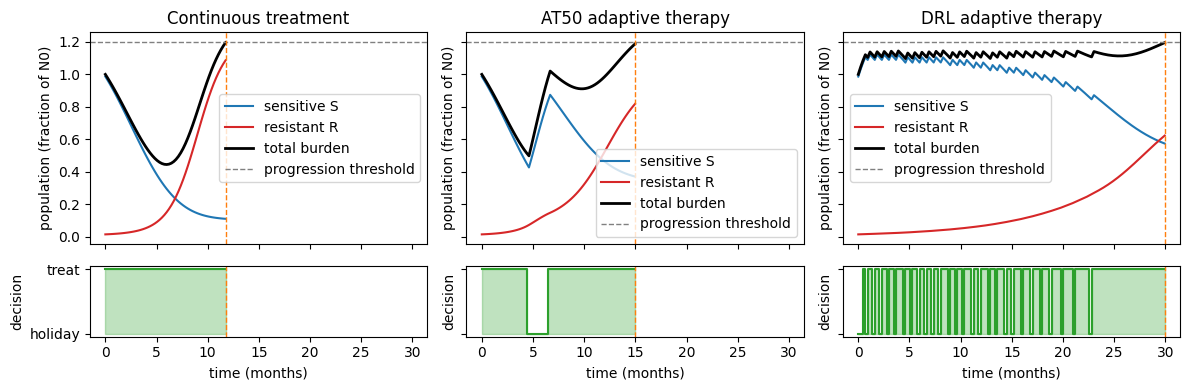

In [11]:
# compare all three strategies
strategies = [("Continuous treatment", ct_policy),
              ("AT50 adaptive therapy", at50_policy),
              ("DRL adaptive therapy", lambda env, obs: agent.choose_action(obs, greedy=True))]
traces = [(name, rollout(env, pol)) for name, pol in strategies]
fig, axes = plt.subplots(2, 3, figsize=(12, 4), sharex=True, gridspec_kw={"height_ratios": [3, 1]}, sharey = 'row')
for i in range(3):
    axes[0, i].set_title(strategies[i][0])
    plot_results(axes[0, i], axes[1, i], traces[i][1], env)
plt.tight_layout()
plt.savefig("adaptive_therapy_comparison.png", dpi=300)